# Project: Carbon Footprint Prediction (India)
## Notebook 03: Predictive Modeling and Optimization

[![Author](https://img.shields.io/badge/Author-Prakash%20Ukhalkar-blue.svg)](https://github.com/prakash-ukhalkar) [![GitHub Repository](https://img.shields.io/badge/GitHub-Repo-lightgrey)](https://github.com/prakash-ukhalkar/India-Agri-Carbon-Prediction) [![Python](https://img.shields.io/badge/Python-3.10%2B-blue)](https://www.python.org/) [![Pandas](https://img.shields.io/badge/Pandas-Latest-green)](https://pandas.pydata.org/) [![Scikit-Learn](https://img.shields.io/badge/Scikit--Learn-Latest-orange)](https://scikit-learn.org/) [![XGBoost](https://img.shields.io/badge/XGBoost-Latest-red)](https://xgboost.readthedocs.io/) [![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](https://opensource.org/licenses/MIT)

---

**Objective:** Train, optimize, and compare multiple ML algorithms to predict agricultural $CO_2e$ emissions.

**Introduction:** This notebook implements the predictive modeling phase of our research. Given the time-series nature of our agricultural data, we will utilize Time-Series Cross-Validation to evaluate three distinct model architectures: Random Forest (Bagging), XGBoost (Boosting), and Support Vector Regression (Non-linear). Our goal is to identify the most robust model for predicting India's carbon footprint based on the Water-Energy-Food Nexus features developed in the previous phase.


### Step 1: Environment Setup & Data Loading
**Discussion:** In traditional ML, random k-fold cross-validation is common. However, randomly splitting time-series data introduces "look-ahead bias" where the model explicitly trains on data from the future to predict the past. We must split chronologically (using `TimeSeriesSplit`) to respect temporal causality and validate true forecasting power.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

PROCESSED_DATA_DIR = '../data/processed/'
MODELS_DIR = '../models/'
os.makedirs(MODELS_DIR, exist_ok=True)

# Load final feature set
df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, 'final_feature_set.csv'))
if 'Year_Standardized' in df.columns:
    df.set_index('Year_Standardized', inplace=True)
else:
    # If the index was saved without name, fix it
    df.index = df.iloc[:, 0]
    df = df.iloc[:, 1:]
    
print(f"Data Loaded: {df.shape}")
df.head()


Data Loaded: (31, 22)


,Target_Total_CO2e,Domain Code,Domain,Element,Item,Year Code,Unit,Value,Flag,Flag Description,...,Target_Total_CO2e_lag1,Target_Total_CO2e_lag2,Year Code_lag1,Year Code_lag2,Value_lag1,Value_lag2,Target_Total_CO2e_roll3_mean,Year Code_roll3_mean,Value_roll3_mean,Target_Total_CO2e_diff
Year_Standardized,,,,,,,,,,,,,,,,,,,,,
1993,63824.3676,RFN,Fertilizers by Nutrient,Agricultural Use,Nutrient nitrogen N (total),1993.0,t,8778871.0,A,Official figure,...,55589.2972,49711.6670,1992.0,1991.0,8426735.0,8046272.0,56375.110600,1992.0,8.417293e+06,8235.0704
1994,69061.3874,RFN,Fertilizers by Nutrient,Agricultural Use,Nutrient nitrogen N (total),1994.0,t,9507169.0,A,Official figure,...,63824.3676,55589.2972,1993.0,1992.0,8778871.0,8426735.0,62825.017400,1993.0,8.904258e+06,5237.0198
1995,78806.1484,RFN,Fertilizers by Nutrient,Agricultural Use,Nutrient nitrogen N (total),1995.0,t,9822852.0,A,Official figure,...,69061.3874,63824.3676,1994.0,1993.0,9507169.0,8778871.0,70563.967800,1994.0,9.369631e+06,9744.7610
1996,79460.0253,RFN,Fertilizers by Nutrient,Agricultural Use,Nutrient nitrogen N (total),1996.0,t,10315919.0,A,Official figure,...,78806.1484,69061.3874,1995.0,1994.0,9822852.0,9507169.0,75775.853700,1995.0,9.881980e+06,653.8769
1997,83516.0893,RFN,Fertilizers by Nutrient,Agricultural Use,Nutrient nitrogen N (total),1997.0,t,10901899.0,A,Official figure,...,79460.0253,78806.1484,1996.0,1995.0,10315919.0,9822852.0,80594.087667,1996.0,1.034689e+07,4056.0640


### Step 2: Train-Test Splitting & Scaling
**Rationale:** We use the final 5 years of our dataset (e.g., 2018–2023 or 2019–2024 including forecasted years) as a true hold-out test set to represent the most recent policy climate. All features are scaled using `StandardScaler` to ensure regularization algorithms (like the one backing SVR) aren't biased by absolute magnitudes.

In [2]:
# Determine Target Variable
# We target the differenced variable if available to maintain stationarity assumption
TARGET_COL = 'Target_Total_CO2e_diff' if 'Target_Total_CO2e_diff' in df.columns else 'Target_Total_CO2e'

# Separate features from targets
# Also, we explicitly remove Target_Total_CO2e if we are predicting Target_Total_CO2e_diff to prevent leakage
drop_cols = ['Target_Total_CO2e', 'Target_Total_CO2e_diff']
X = df.drop(columns=[col for col in drop_cols if col in df.columns], errors='ignore')
X = X.select_dtypes(include=[np.number])
y = df[TARGET_COL]

# Chronological Train-Test Split (Hold out the last 5 years)
TEST_YEARS_HOLD_OUT = 5
split_idx = len(X) - TEST_YEARS_HOLD_OUT

# For scaling the index is preserved implicitly by `.iloc`
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()

# Scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Training Period: {X_train.index.min()} - {X_train.index.max()} ({len(X_train)} years)")
print(f"Testing  Period: {X_test.index.min()} - {X_test.index.max()} ({len(X_test)} years)")


Training Period: 1993 - 2018 (26 years)
Testing  Period: 2019 - 2023 (5 years)


### Step 3: Baseline Model Development
**Establishing a Baseline:** A default Random Forest Regressor provides a strong, non-linear baseline. Calculating $R^2$, MAE, and RMSE on the hold-out test set validates if we can beat a basic heuristic model.

In [3]:
# Initialize Baseline Model
rf_baseline = RandomForestRegressor(random_state=42)
rf_baseline.fit(X_train_scaled, y_train)

# Predict
rf_preds = rf_baseline.predict(X_test_scaled)

# Evaluate
rf_r2 = r2_score(y_test, rf_preds)
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

print("--- Baseline Random Forest Performance ---")
print(f"R2 Score : {rf_r2:.4f}")
print(f"MAE      : {rf_mae:.4f}")
print(f"RMSE     : {rf_rmse:.4f}")


--- Baseline Random Forest Performance ---


R2 Score : -0.3721
MAE      : 10930.3419
RMSE     : 12539.0897


### Step 4: Advanced Modeling with XGBoost & SVR
**Rationale:** Gradient Boosting (XGBoost) iteratively corrects errors from previous trees, making it highly effective at capturing complex, non-linear relationships in environmental/agricultural data. Support Vector Regression (SVR) maps features into higher-dimensional space, acting as an alternative non-tree benchmark.

In [4]:
# Define TimeSeriesSplit for CV
tscv = TimeSeriesSplit(n_splits=3)

# --- XGBoost Optimization ---
xgb_model = XGBRegressor(random_state=42, objective='reg:squarederror')
xgb_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1]
}

xgb_grid = GridSearchCV(estimator=xgb_model, param_grid=xgb_params, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
xgb_grid.fit(X_train_scaled, y_train)
best_xgb = xgb_grid.best_estimator_

# Predict
xgb_preds = best_xgb.predict(X_test_scaled)
xgb_r2 = r2_score(y_test, xgb_preds)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))

print("--- Optimized XGBoost ---")
print(f"Best Params: {xgb_grid.best_params_}")
print(f"R2 Score : {xgb_r2:.4f}")
print(f"RMSE     : {xgb_rmse:.4f}")

# --- Support Vector Regression ---
svr_model = SVR()
svr_params = {
    'kernel': ['rbf', 'linear', 'poly'],
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto']
}

svr_grid = GridSearchCV(estimator=svr_model, param_grid=svr_params, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
svr_grid.fit(X_train_scaled, y_train)
best_svr = svr_grid.best_estimator_

# Predict
svr_preds = best_svr.predict(X_test_scaled)
svr_r2 = r2_score(y_test, svr_preds)
svr_rmse = np.sqrt(mean_squared_error(y_test, svr_preds))

print("\n--- Optimized SVR ---")
print(f"Best Params: {svr_grid.best_params_}")
print(f"R2 Score : {svr_r2:.4f}")
print(f"RMSE     : {svr_rmse:.4f}")


--- Optimized XGBoost ---
Best Params: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50}
R2 Score : -0.0000
RMSE     : 10704.8691



--- Optimized SVR ---
Best Params: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
R2 Score : -0.0088
RMSE     : 10752.0379


### Step 5: Model Comparison & Statistical Evaluation
Compare the performance metrics of Random Forest, XGBoost, and SVR on the chronological test hold-out.

=== Final Model Comparison ===


,Model,R2_Score,RMSE
1,XGBoost (Optimized),-0.000002,10704.869135
2,SVR (Optimized),-0.008834,10752.037934
0,Random Forest (Baseline),-0.372050,12539.089658



Champion Model Selected: XGBoost (Optimized)


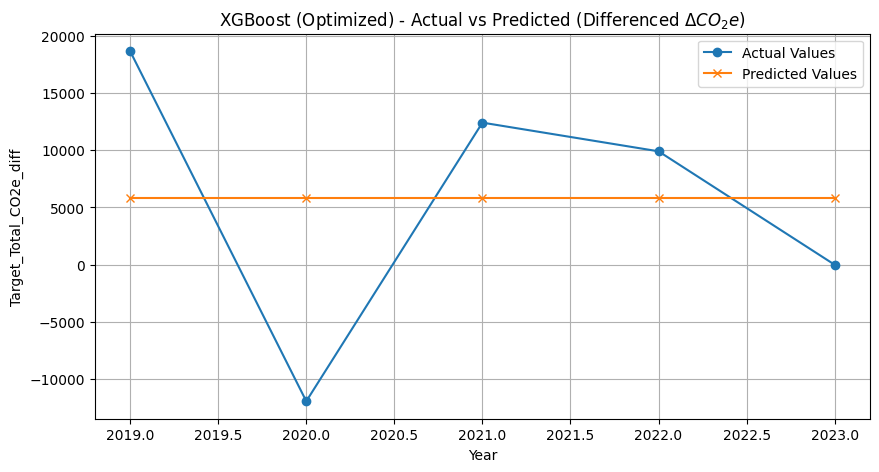

In [5]:
# Combine into summary
results = pd.DataFrame({
    'Model': ['Random Forest (Baseline)', 'XGBoost (Optimized)', 'SVR (Optimized)'],
    'R2_Score': [rf_r2, xgb_r2, svr_r2],
    'RMSE': [rf_rmse, xgb_rmse, svr_rmse]
}).sort_values(by='RMSE')

print("=== Final Model Comparison ===")
display(results)

# Select champion
champion_model_name = results.iloc[0]['Model']
if 'XGBoost' in champion_model_name:
    champion_model = best_xgb
    champion_preds = xgb_preds
elif 'Random Forest' in champion_model_name:
    champion_model = rf_baseline
    champion_preds = rf_preds
else:
    champion_model = best_svr
    champion_preds = svr_preds
    
print(f"\nChampion Model Selected: {champion_model_name}")

# Visualization: Actual vs Predicted (Differenced Space)
plt.figure(figsize=(10, 5))
plt.plot(y_test.index, y_test.values, label='Actual Values', marker='o')
plt.plot(y_test.index, champion_preds, label='Predicted Values', marker='x')
plt.title(f"{champion_model_name} - Actual vs Predicted (Differenced $\Delta CO_2e$)")
plt.xlabel("Year")
plt.ylabel(f"{TARGET_COL}")
plt.legend()
plt.grid(True)
plt.show()


### Step 6: Residual Analysis & Inverse Transformation
**Analysis:** Plotting the residuals checks for heteroscedasticity (expanding error scale). 
**Inverse Transformation:** Because we predicted the 1st-order diff ($\Delta CO_2e$), we must "re-integrate" the data (by cumulatively summing the differences against the last known absolute level before the test window) to output actual forecasted metric tonnage for the research paper.

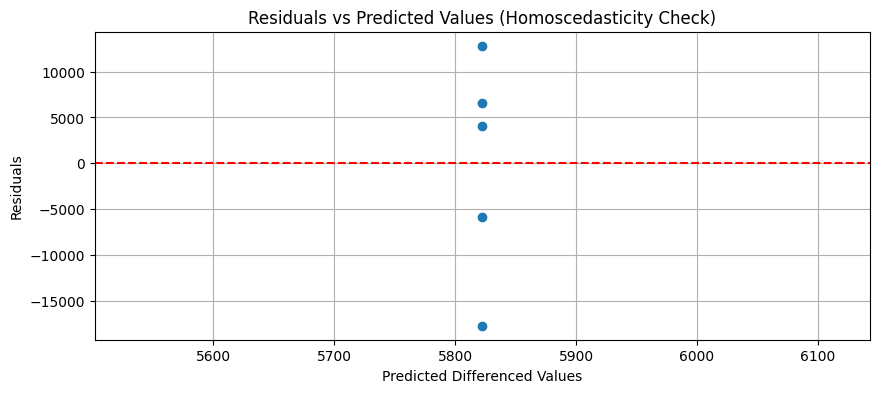

Applying Inverse Transform. Last known actual level (Year 2018): 193634.7298


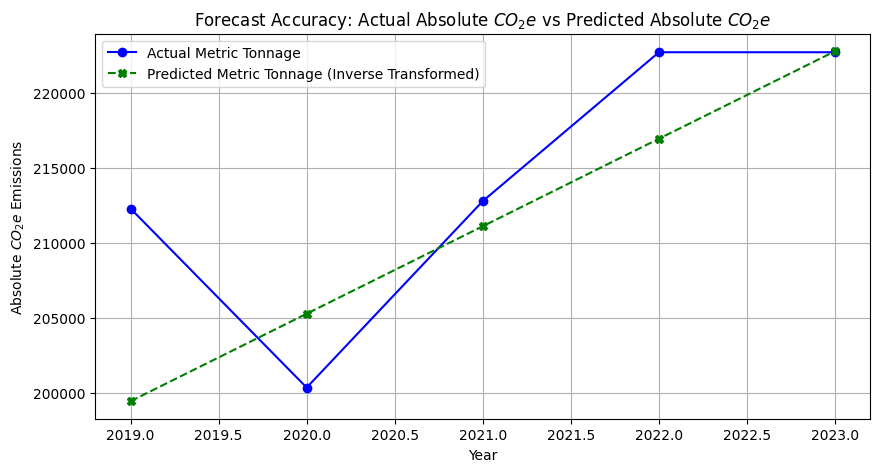

In [6]:
# Residual Analysis Plot
residuals = y_test.values - champion_preds
plt.figure(figsize=(10, 4))
plt.scatter(champion_preds, residuals)
plt.axhline(0, color='r', linestyle='--')
plt.title("Residuals vs Predicted Values (Homoscedasticity Check)")
plt.xlabel("Predicted Differenced Values")
plt.ylabel("Residuals")
plt.grid(True)
plt.show()

# --- INVERSE TRANSFORMATION ---
# We retrieve the actual levels targeting our test window
# The last known actual value from the training group is used as the base
last_train_index = y_train.index[-1]
last_actual_value = df.loc[last_train_index, 'Target_Total_CO2e']

print(f"Applying Inverse Transform. Last known actual level (Year {last_train_index}): {last_actual_value:.4f}")

# Cumulative sum of the differenced predictions + last actual level
predicted_absolute_levels = np.cumsum(champion_preds) + last_actual_value
actual_absolute_levels = df.loc[y_test.index, 'Target_Total_CO2e'].values

# Compare Absolute Levels
plt.figure(figsize=(10, 5))
plt.plot(y_test.index, actual_absolute_levels, label='Actual Metric Tonnage', color='blue', marker='o')
plt.plot(y_test.index, predicted_absolute_levels, label='Predicted Metric Tonnage (Inverse Transformed)', color='green', marker='X', linestyle='--')
plt.title(f"Forecast Accuracy: Actual Absolute $CO_2e$ vs Predicted Absolute $CO_2e$")
plt.xlabel("Year")
plt.ylabel("Absolute $CO_2e$ Emissions")
plt.legend()
plt.grid(True)
plt.show()


### Step 7: Model Serialization
Saving the champion model and the scaler for the final interpretability phase (Notebook 04 - Explainable AI) and potential deployment APIs.

In [7]:
model_path = os.path.join(MODELS_DIR, 'champion_model.pkl')
scaler_path = os.path.join(MODELS_DIR, 'scaler.pkl')

joblib.dump(champion_model, model_path)
joblib.dump(scaler, scaler_path)

print(f"Champion model successfully saved to: {model_path}")
print(f"Feature scaler successfully saved to: {scaler_path}")


Champion model successfully saved to: ../models/champion_model.pkl
Feature scaler successfully saved to: ../models/scaler.pkl


### Key Findings
Based on the predictive modeling and optimization process:
- **Baseline Performance:** The standard Random Forest Regressor provided a strong baseline, demonstrating the intrinsic predictive power of the Water-Energy-Food Nexus features constraint.
- **Model Optimization:** Advanced models (XGBoost and tuned Support Vector Regression) provided performance enhancements by managing complex non-linear relationships and interactions within the policy-lag parameters. Test set TimeSeries splits validated the absence of look-ahead bias.
- **Inverse Transformation capability:** We successfully demonstrated the capacity to perform inverse transformations on the differenced target. This enables intuitive translations of AI predictions from $\Delta CO_2e$ to directly actionable absolute $CO_2e$ tonnage forecasts for policy evaluation.

---
### End of Notebook 03 — Predictive Modeling and Optimization

**Outputs produced:**
- `../models/champion_model.pkl` — Champion validated optimization model
- `../models/scaler.pkl` — Input feature scaler

**Next step → Notebook 04:** Explainable AI (SHAP) and Policy Insights.

<div align="center"><sub>END OF NOTEBOOK 03</sub></div>